# Multimodal Sun — proof-of-concept summary (Phases 0–4)

## What this proof of concept is for

**Multimodal Sun (MMS)** is a planned machine-learning-ready dataset that puts
observations of the Sun from several instruments into one common, queryable form. It is
modelled on the [Multimodal Universe](https://github.com/MultimodalUniverse/MultimodalUniverse),
which does the same for astronomical surveys: every source is stored with a sky position,
and data from different surveys are joined by cross-matching on that position
(HATS-partitioned catalogues read with LSDB).

The proof of concept answers one question: **can we build the smallest possible sample
that contains every target modality, matched in time and space, coaligned, and stored in
a table that supports a cross-match query — in a way that grows to many epochs without
redesign?** The four modalities are:

| Instrument | What it measures | Why it is here |
|---|---|---|
| **SDO/AIA** | full-disk EUV images, 7 channels (~0.05–20 MK plasma), 0.6″ pixels, 12 s cadence | the reference: always on, well calibrated, wide temperature coverage |
| **SDO/HMI** | photospheric line-of-sight magnetic field, 0.5″ pixels, 45 s cadence | the magnetic driver beneath the corona |
| **Hinode/XRT** | soft X-ray images (hot, few-MK and flare plasma), ~1″ pixels | hot-plasma imaging; filters vary with the observing program |
| **Hinode/EIS** | EUV *spectra*: line intensities, Doppler velocities and widths | the only spectroscopic modality, and the scarcest — small field of view, built up slit position by slit position |

Because EIS observes rarely and slowly, **an EIS raster is the anchor**: everything else
is chosen to match it.

## What the pipeline does

| Phase | Step | Output |
|---|---|---|
| 0 | pick the anchor EIS raster (`config/epochs.yaml`) | — |
| 1 | metadata-only discovery: list AIA, HMI and XRT candidates around the raster | `data/manifest/<epoch>/cand_*.parquet` |
| 2 | match in time and space; choose the minimal file set | `match.parquet`, `match_report.json` |
| 3a | download only the matched files (AIA/HMI as small cutouts) | `data/raw/` |
| 3b | calibrate each product to science-ready maps on its own pixel grid | `data/prep/`, `products.parquet` |
| 4 | coalign EIS and XRT to AIA, resample everything onto one grid, write tables | `data/aligned/<epoch>/` |

Phase 5 — writing the tables as a HATS catalogue — is **not implemented yet**; the
Phase 4 tables already carry Carrington longitude/latitude per pixel so that step is thin.

**Current state:** Phases 0–4 run end to end for one anchor epoch,
`eis_20210306_064444`: a 5-minute EIS raster (2021-03-06 06:44:44–06:49:34 UT) of
NOAA AR 12807 near disk centre, taken during a coordinated Hinode flare watch, so XRT
was pointed at the same region. The whole sample is about 50 MB.

## How to read this notebook

The notebook only *reads* pipeline outputs (`data/manifest`, `data/prep`,
`data/aligned`); it downloads and recomputes nothing. Sections:

1. what is in the sample and when each product was observed;
2. where each instrument was looking;
3. the EIS spectral products;
4. how well the coalignment worked;
5. all channels on the common grid;
6. cross-match queries — the operation the final dataset is built for;
7. disk usage.

Conventions used throughout: positions are **helioprojective** arcsec (Solar X/Y, as seen
from the observer) or **Carrington** heliographic degrees (fixed to the rotating Sun);
**t_ref** is the EIS raster mid-time, to which all maps are rotated; **Δt** is an
observation time minus t_ref.

Environment variables: `MMSUN_EPOCH` (default `anchor`) picks the epoch;
`MMSUN_CONFIG` points at an alternative `pipeline.yaml` (the offline test uses this).

### Setup

Load the configuration and this epoch's manifests (`epoch.json` for the raster metadata,
`products.parquet` for every calibrated product, `shifts.json` for the coalignment
result), define small plotting helpers, and print the epoch summary and the Phase 2
matching verdict for each modality.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "config").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sunpy, sunpy.map, sunpy.visualization.colormaps  # registers sdoaia*/hinodexrt colormaps
sunpy.log.setLevel("WARNING")
from astropy.io import fits
from mmsun.config import load_config, active_epochs, paths_for
from mmsun.coalign import world_arcsec

cfg = load_config(os.environ.get("MMSUN_CONFIG"))
ep = active_epochs(cfg, [os.environ.get("MMSUN_EPOCH", "anchor")])[0]
P = paths_for(cfg, ep["id"])
info = json.loads((P.manifest / "epoch.json").read_text())
prods = pd.read_parquet(P.manifest / "products.parquet")
shifts = json.loads((P.aligned / "shifts.json").read_text())
t_ref = pd.Timestamp(info["t_mid"])
plt.rcParams.update({"figure.dpi": 110, "image.origin": "lower", "axes.titlesize": 9,
                     "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7})

def extent(m, d=(0, 0)):
    tx, ty = world_arcsec(m)
    return [tx.min() + d[0], tx.max() + d[0], ty.min() + d[1], ty.max() + d[1]]

def box_xy(b):
    return [b[0], b[1], b[1], b[0], b[0]], [b[2], b[2], b[3], b[3], b[2]]

def robust(a, lo=1, hi=99.5):
    a = np.asarray(a, float); f = a[np.isfinite(a)]
    return (np.percentile(f, lo), np.percentile(f, hi)) if f.size else (0, 1)

print(f"epoch {ep['id']}   {info['date_obs']} -> {info['date_end']}   t_ref = {t_ref}")
print(f"EIS study {info['study']} ({info['study_id']}), {info['nsteps']} steps, slit {info['slit']}, "
      f"FOV {info['fovx']:.0f}\"x{info['fovy']:.0f}\" at ({info['xcen']:.0f}\", {info['ycen']:.0f}\"), NOAA {info['noaa']}")
print(f"title: {info['obstitle']}")
rep = P.manifest / "match_report.json"
if rep.exists():
    for k, v in json.loads(rep.read_text())["verdict"].items():
        print(f"  {k:4s} {v}")

epoch eis_20210306_064444   2021-03-06T06:44:44 -> 2021-03-06T06:49:34   t_ref = 2021-03-06 06:47:09
EIS study cam_flare_hot1_study (598), 25 steps, slit 2", FOV 100"x120" at (3", -197"), NOAA 12807
title: HOP396 Collaboration w/ Chandarayan-2 XSM AR12807
  EIS  ok
  AIA  ok: 25/25 steps matched, 25 frames; 7/7 context channels
  HMI  ok
  XRT  ok (ar): Be_thin dt=+0s (mid -24s), Be_med dt=+0s (mid -3s)


## 1. What is in the sample

"Simultaneous" means something different for each instrument, because an EIS raster is
not a snapshot: it scans its slit across the region over several minutes, so each slit
position (column) has its own time. Phase 2 therefore matches:

* **AIA 193 pseudo-raster** — one AIA 193 Å frame per EIS slit step, the nearest in time
  to that step. Stitching the matching column out of each frame gives an AIA image built
  the same way as the EIS raster, which is what EIS is coaligned against (Section 4).
* **AIA context** (7 EUV channels) and **HMI** — one frame per channel nearest t_ref.
* **XRT** — frames that cover the EIS field of view and lie within 300 s of the raster
  interval; among frames taken during the raster, the one nearest t_ref.

The table below groups the calibrated products by instrument and role, with the range of
Δt = t_obs − t_ref (computed here, so for every row it is relative to the mid-time) and
the size on disk. The pseudo-raster's wide Δt range is expected: its frames follow the
slit across the whole raster.

In [2]:
p = prods.copy()
p["t_obs"] = pd.to_datetime(p["t_obs"], format="ISO8601")
p["dt_s"] = (p["t_obs"] - t_ref).dt.total_seconds().round(1)
p["MB"] = [Path(x).stat().st_size / 1e6 if Path(x).exists() else np.nan for x in p["path"]]
p["role"] = p.get("role", pd.Series(index=p.index, dtype=object)).replace({"nan": ""}).fillna("")
summary = (p.groupby(["modality", "role"], dropna=False)
             .agg(files=("path", "size"), dt_min_s=("dt_s", "min"), dt_max_s=("dt_s", "max"), MB=("MB", "sum"))
             .round(1))
summary

files  dt_min_s  dt_max_s    MB
modality role                                         
AIA      context           7     -11.4       0.3  13.2
         pseudoraster     25    -148.2     139.8  10.4
EIS                       12    -145.0    -145.0   0.3
HMI      context           1     -12.3     -12.3   2.7
XRT                        2     -24.0      -3.2   1.2

The same information as a timeline: black ticks are the EIS slit steps, the grey band is
the raster duration and the dashed red line is t_ref. Each pseudo-raster frame should sit
next to an EIS tick, and the context, HMI and XRT points should cluster near t_ref.

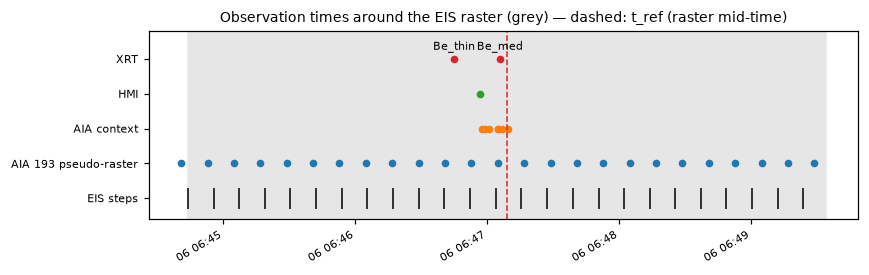

In [3]:
steps = pd.read_parquet(P.manifest / "eis_steps.parquet"); steps["t_step"] = pd.to_datetime(steps["t_step"], format="ISO8601")
fig, ax = plt.subplots(figsize=(8, 2.6))
rows = {"EIS steps": 0, "AIA 193 pseudo-raster": 1, "AIA context": 2, "HMI": 3, "XRT": 4}
ax.vlines(steps.t_step, -0.3, 0.3, color="k", lw=1)
ax.axvspan(pd.Timestamp(info["date_obs"]), pd.Timestamp(info["date_end"]), color="0.9", zorder=0)
sel = {"AIA 193 pseudo-raster": (p.modality == "AIA") & (p.role == "pseudoraster"),
       "AIA context": (p.modality == "AIA") & (p.role == "context"),
       "HMI": p.modality == "HMI", "XRT": p.modality == "XRT"}
for name, s in sel.items():
    ax.plot(p.loc[s, "t_obs"], np.full(s.sum(), rows[name]), "o", ms=4, label=name)
for r in p[p.modality == "XRT"].itertuples():
    ax.annotate(r.filter, (r.t_obs, 4), xytext=(0, 6), textcoords="offset points", fontsize=7, ha="center")
ax.axvline(t_ref, color="C3", ls="--", lw=1)
ax.set_yticks(list(rows.values()), list(rows.keys())); ax.set_ylim(-0.6, 4.8)
ax.set_title("Observation times around the EIS raster (grey) — dashed: t_ref (raster mid-time)")
fig.autofmt_xdate(); plt.tight_layout()

## 2. Spatial context

Where each instrument was looking. AIA and HMI were downloaded as cutouts around the EIS
field of view (plus a margin), so they always contain it; XRT frames were only accepted if
they cover at least 90% of it.

Left: the AIA 193 Å context cutout with the EIS field of view as given by its header
(dashed white) and after coalignment (solid cyan), and the XRT fields of view (orange,
also after coalignment). Right: the HMI line-of-sight magnetic field over the same area,
with the same outlines — the bright EUV loops should connect regions of opposite polarity.

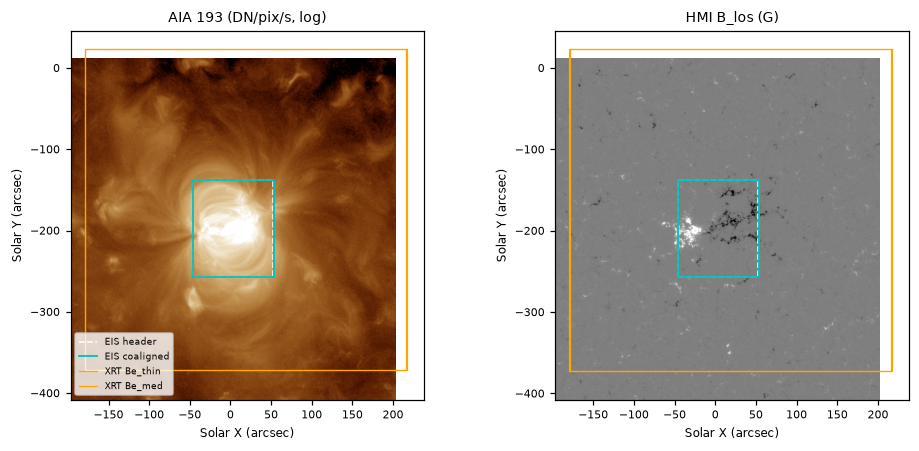

In [4]:
def first(mod, role=None, chan=None):
    s = p[p.modality == mod]
    if role: s = s[s.role == role]
    if chan is not None: s = s[s.channel.astype(str) == str(chan)]
    return sunpy.map.Map(s.iloc[0].path) if len(s) else None

a193, hmi = first("AIA", "context", 193), first("HMI")
b = info["box_arcsec"]; d = (shifts["EIS"]["dx"], shifts["EIS"]["dy"])
bt = [b[0] + d[0], b[1] + d[0], b[2] + d[1], b[3] + d[1]]
fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, m, cmap, title in [(axs[0], a193, "sdoaia193", "AIA 193 (DN/pix/s, log)"),
                           (axs[1], hmi, "gray", "HMI B_los (G)")]:
    if m is None: ax.set_visible(False); continue
    dat = m.data if cmap == "gray" else np.log10(np.clip(m.data, 1, None))
    vmin, vmax = (-500, 500) if cmap == "gray" else robust(dat)
    ax.imshow(dat, extent=extent(m), cmap=cmap, vmin=vmin, vmax=vmax)
    ax.plot(*box_xy(b), "w--", lw=1, label="EIS header")
    ax.plot(*box_xy(bt), "c-", lw=1.2, label="EIS coaligned")
    for r in p[p.modality == "XRT"].itertuples():
        xm = sunpy.map.Map(r.path); key = f"XRT_{r.filter}"
        e = extent(xm, (shifts.get(key, {}).get("dx", 0), shifts.get(key, {}).get("dy", 0)))
        ax.plot(*box_xy(e), "-", lw=0.8, color="orange", label=f"XRT {r.filter}")
    ax.set_title(title); ax.set_xlabel("Solar X (arcsec)"); ax.set_ylabel("Solar Y (arcsec)")
axs[0].legend(fontsize=6, loc="lower left")
plt.tight_layout()

## 3. EIS spectral products

EIS records a spectrum at every pixel, in a set of narrow wavelength *windows*, each
centred on an emission line formed at a characteristic temperature. Phase 3b turns the
spectra into maps in two ways:

* **window-integrated intensity** — the spectrum summed over each window, giving one
  image per window (titles name the main line), from cooler lines such as Fe XII (~1.5 MK)
  to the flare line Fe XXIII 263.8 Å (~14 MK);
* **Gaussian fit** of Fe XII 192.39 Å — the line's Doppler velocity (red = away from the
  observer, blue = towards) and its width, which carries information on unresolved motions.

The maps are shown at EIS's native sampling: 4″ between slit positions in x and 1″ along
the slit in y. Long-wavelength windows are shifted in y by ~17″ on the detector, so
blank rows at their top or bottom are expected.

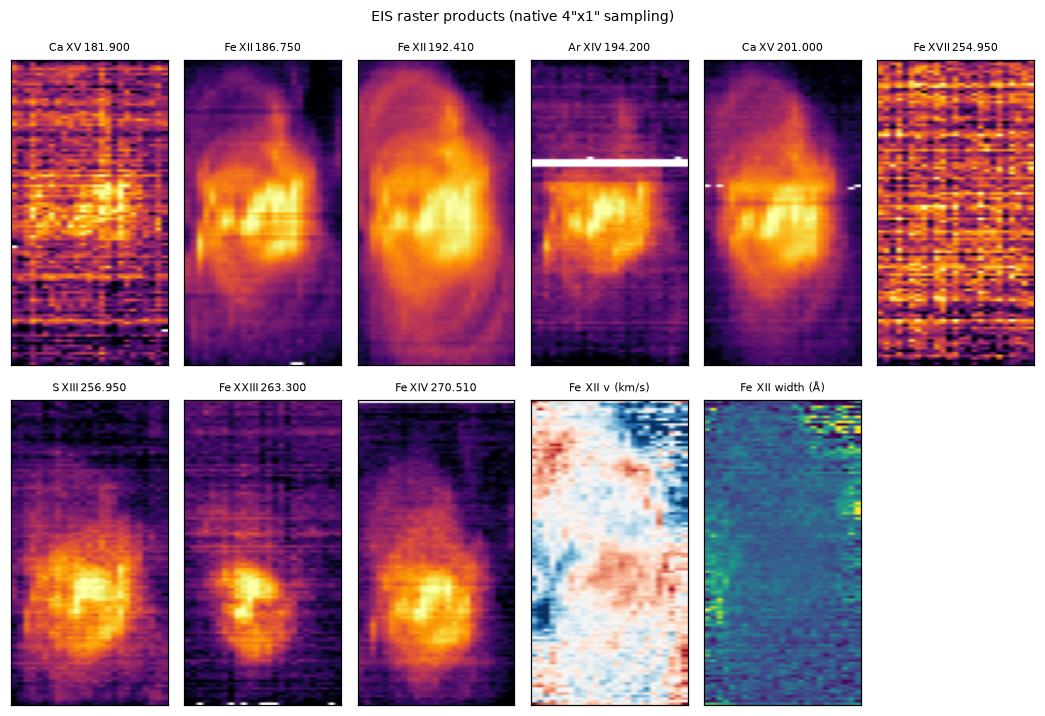

In [5]:
e = p[p.modality == "EIS"].copy()
wins = e[e["product"].str.startswith("eis_win")].sort_values("product")
fits_ = e[e["product"].str.startswith("eis_fit")]
items = list(wins.itertuples()) + [r for r in fits_.itertuples() if r.product.endswith(("_vel", "_wid"))]
n = len(items); ncol = 6; nrow = int(np.ceil(n / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(1.6 * ncol, 3.3 * nrow), squeeze=False)
for ax, r in zip(axs.ravel(), items):
    m = sunpy.map.Map(r.path); dat = np.asarray(m.data, float)
    if r.product.endswith("_vel"):
        ax.imshow(dat, extent=extent(m), cmap="RdBu_r", vmin=-15, vmax=15, aspect="auto"); lab = "Fe XII v (km/s)"
    elif r.product.endswith("_wid"):
        ax.imshow(dat, extent=extent(m), cmap="viridis", vmin=robust(dat)[0], vmax=robust(dat)[1], aspect="auto"); lab = "Fe XII width (Å)"
    else:
        ld = np.log10(np.clip(dat, 1e-3, None)); ld[~np.isfinite(dat)] = np.nan
        ax.imshow(ld, extent=extent(m), cmap="inferno", vmin=robust(ld, 2, 99.5)[0],
                  vmax=robust(ld, 2, 99.5)[1], aspect="auto")
        lab = r.line.replace(" ", "\u2009")
    ax.set_title(lab, fontsize=7); ax.set_xticks([]); ax.set_yticks([])
for ax in axs.ravel()[n:]: ax.set_visible(False)
plt.suptitle("EIS raster products (native 4\"x1\" sampling)", fontsize=9); plt.tight_layout()

## 4. Coalignment diagnostics

Each instrument's header pointing is only accurate to a few arcseconds (EIS sometimes to
tens), which is larger than the pixels we want to compare. AIA is the reference, and the
other instruments are shifted onto it:

* **EIS** is cross-correlated with the AIA 193 **pseudo-raster** from Section 1, using the
  Fe XII 192 Å intensity, which forms at a similar temperature to AIA 193. Using the
  pseudo-raster rather than a single AIA frame means each EIS column is compared with AIA
  at that column's own time.
* **XRT** is cross-correlated with whichever of AIA 335, 94 or 211 matches it best, after
  rotating for the Sun's rotation between the two observation times.

The table lists, for each instrument, the shift found (convention: **true position =
header position + shift**), the correlation before and after shifting, and whether the
result was flagged. The search runs over ±40″, coarse to fine (4″ → 1″ → 0.25″ steps). A
shift is flagged if the correlation after shifting is below 0.5 or there was no AIA
reference; a flag means the result needs a human look. A shift close to ±40″ also needs
a look (the true offset may lie outside the search range), but is not flagged
automatically — check the dx/dy columns.

In [6]:
rows_ = []
for k, v in shifts.items():
    rows_.append(dict(instrument=k, dx_arcsec=v.get("dx"), dy_arcsec=v.get("dy"),
                      r_before=v.get("r_before"), r_after=v.get("r_after"),
                      reference=v.get("reference", v.get("note")), flagged=v.get("flagged")))
pd.DataFrame(rows_).round(3)

,instrument,dx_arcsec,dy_arcsec,r_before,r_after,reference,flagged
0,EIS,0.75,0.0,0.986,0.987,AIA 193 pseudo-raster,False
1,XRT_Be_thin,1.50,-1.5,0.942,0.943,AIA 211,False
2,XRT_Be_med,0.50,-1.5,0.908,0.911,AIA 211,False


The EIS coalignment, visually. From left: the EIS Fe XII intensity; the AIA 193
pseudo-raster sampled at the EIS header pointing; the same after applying the shift; and
the correlation for each trial shift on the coarse 4″ grid, with the final shift (after
the 1″ and 0.25″ refinements) as a red cross. A good result shows the two right-hand images looking like the EIS one, and
a single clear correlation peak away from the edges of the search grid.

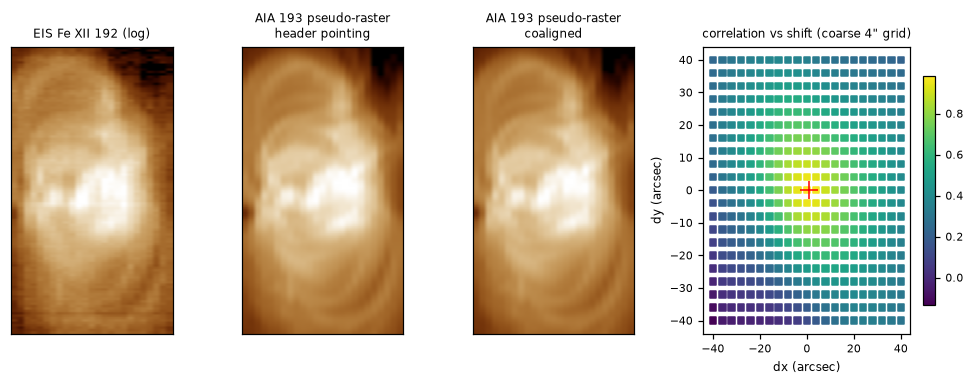

In [7]:
dg = np.load(P.aligned / "coalign_diag.npz")
if "eis_target" in dg:
    eis_t = np.log10(np.clip(dg["eis_target"], 1e-3, None))
    fig, axs = plt.subplots(1, 4, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.6]})
    for ax, img, t in [(axs[0], eis_t, "EIS Fe XII 192 (log)"),
                       (axs[1], dg["pr_before"], "AIA 193 pseudo-raster\nheader pointing"),
                       (axs[2], dg["pr_after"], "AIA 193 pseudo-raster\ncoaligned")]:
        ax.imshow(img, cmap="sdoaia193", aspect="auto", vmin=robust(img)[0], vmax=robust(img)[1])
        ax.set_title(t, fontsize=8); ax.set_xticks([]); ax.set_yticks([])
    s = dg["eis_surface"]
    sc = axs[3].scatter(s[:, 0], s[:, 1], c=s[:, 2], cmap="viridis", s=18, marker="s")
    axs[3].plot(shifts["EIS"]["dx"], shifts["EIS"]["dy"], "r+", ms=12)
    axs[3].set_title("correlation vs shift (coarse 4\" grid)", fontsize=8)
    axs[3].set_xlabel("dx (arcsec)"); axs[3].set_ylabel("dy (arcsec)"); plt.colorbar(sc, ax=axs[3], shrink=0.8)
    plt.tight_layout()

## 5. All modalities on the common grid

With the shifts known, Phase 4 resamples every channel onto **one grid**: 2″ pixels in
helioprojective coordinates, covering the coaligned EIS field of view, as seen at t_ref
(each map is rotated from its own observation time to t_ref first). After this step the
same pixel index means the same place on the Sun in every layer. This is the "image" form
of the dataset, stored as `stack.fits` with one extension per channel.

Shown below: the 7 AIA channels, the AIA 193 pseudo-raster, the HMI magnetogram, the XRT
filters and a selection of EIS windows plus the Fe XII velocity and width. Each title
gives the channel and its Δt.

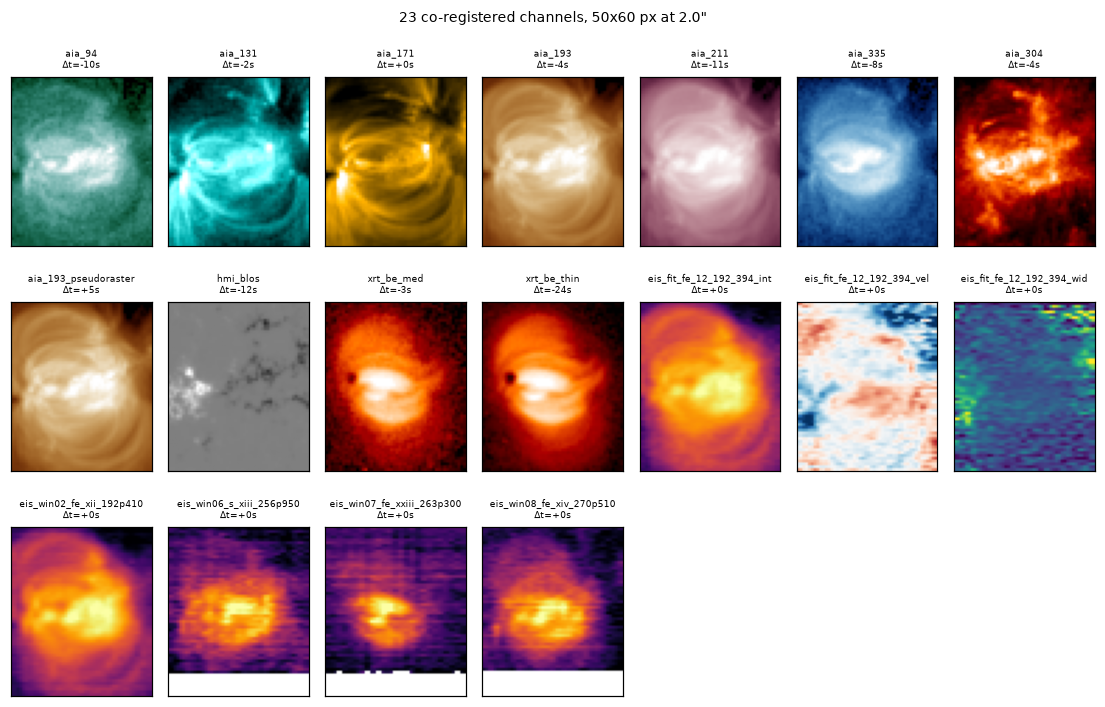

In [8]:
hd = fits.open(P.aligned / "stack.fits")
keep_eis = ("192P410", "263P300", "270P510", "256P950")   # Fe XII, Fe XXIII, Fe XIV, S XIII
layers = [h for h in hd[1:] if not h.name.upper().startswith("EIS_WIN") or h.name.upper().endswith(keep_eis)]
pref = ["AIA_94", "AIA_131", "AIA_171", "AIA_193", "AIA_211", "AIA_335", "AIA_304", "AIA_193_PSEUDORASTER",
        "HMI_BLOS"]
layers.sort(key=lambda h: (pref.index(h.name.upper()) if h.name.upper() in pref else 50 + ("XRT" not in h.name.upper()), h.name))
g0 = hd[1].header
ext = [g0["CRVAL1"] - g0["CDELT1"] / 2, g0["CRVAL1"] + g0["CDELT1"] * (g0["NAXIS1"] - 0.5),
       g0["CRVAL2"] - g0["CDELT2"] / 2, g0["CRVAL2"] + g0["CDELT2"] * (g0["NAXIS2"] - 0.5)]
cmaps = {"AIA_94": "sdoaia94", "AIA_131": "sdoaia131", "AIA_171": "sdoaia171", "AIA_193": "sdoaia193",
         "AIA_211": "sdoaia211", "AIA_335": "sdoaia335", "AIA_304": "sdoaia304", "AIA_193_PSEUDORASTER": "sdoaia193"}
ncol = 7; nrow = int(np.ceil(len(layers) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(1.45 * ncol, 2.25 * nrow), squeeze=False)
for ax, h in zip(axs.ravel(), layers):
    a = h.data.astype(float); name = h.name.upper()
    if name.startswith("HMI"):
        ax.imshow(a, extent=ext, cmap="gray", vmin=-800, vmax=800)
    elif name.endswith("_VEL"):
        ax.imshow(a, extent=ext, cmap="RdBu_r", vmin=-15, vmax=15)
    elif name.endswith("_WID"):
        ax.imshow(a, extent=ext, cmap="viridis", vmin=robust(a)[0], vmax=robust(a)[1])
    else:
        la = np.log10(np.clip(a, 1e-3, None)); la[~np.isfinite(a)] = np.nan
        cm = cmaps.get(name, "hinodexrt" if name.startswith("XRT") else "inferno")
        ax.imshow(la, extent=ext, cmap=cm, vmin=robust(la)[0], vmax=robust(la)[1])
    ax.set_title(f"{name.lower()}\nΔt={h.header['DT_S']:+.0f}s", fontsize=6)
    ax.set_xticks([]); ax.set_yticks([])
for ax in axs.ravel()[len(layers):]: ax.set_visible(False)
plt.suptitle(f"{len(hd) - 1} co-registered channels, {g0['NAXIS1']}x{g0['NAXIS2']} px at {g0['CDELT1']:.1f}\"", fontsize=9)
plt.tight_layout()

## 6. Cross-match queries

The point of the dataset is to ask questions *across* instruments: "for this place on the
Sun, what did every instrument see?" In the Multimodal Universe, that is a cross-match on
sky position (RA/Dec). Here the equivalent position is **Carrington longitude/latitude**:
heliographic coordinates fixed to the rotating Sun, so a feature keeps its coordinates
from one observation to the next. Phase 4 stores them for every pixel, in two tables:

* `pixels.parquet` — one row per common-grid pixel, one column per channel (the table
  form of `stack.fits`);
* `native.parquet` — one row per *original* pixel per channel, at each instrument's own
  resolution, with no resampling.

Both carry over unchanged to a HATS catalogue in Phase 5, with `lon_carr`/`lat_carr` in
place of RA/Dec. Three queries follow.

**6a — cone query on the common-grid table** (`pixels.parquet`). Find the brightest XRT
pixel, then take every grid pixel within 1° of it (great-circle distance on the solar
sphere, ~12 Mm) and summarise what all modalities recorded there. Because every channel is
already on the same grid, this is a single table filter.

In [9]:
px = pd.read_parquet(P.aligned / "pixels.parquet")
xrt_cols = [c for c in px.columns if c.startswith("xrt_") and not c.startswith("dt_")]

def hav_deg(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, (lon1, lat1, lon2, lat2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return np.degrees(2 * np.arcsin(np.sqrt(a)))

key = xrt_cols[0] if xrt_cols else "aia_94"
peak = px.loc[px[key].idxmax()]
radius_deg = 1.0     # ~12 Mm on the solar surface
cone = px[hav_deg(px.lon_carr, px.lat_carr, peak.lon_carr, peak.lat_carr) <= radius_deg]
show = ["lon_carr", "lat_carr", "mu", key, "aia_94", "aia_335", "aia_193_pseudoraster", "hmi_blos"] + \
       [c for c in px.columns if c.startswith("eis_win07") or c.endswith("_vel")]
show = [c for c in show if c in cone and not c.startswith("dt_")]
print(f"cone of {radius_deg}° around brightest {key} pixel at (lon, lat) = "
      f"({peak.lon_carr:.2f}°, {peak.lat_carr:.2f}°): {len(cone)} grid pixels")
cone[show].describe().loc[["mean", "std", "min", "max"]].round(2)

cone of 1.0° around brightest xrt_Be_thin pixel at (lon, lat) = (153.29°, -18.81°): 221 grid pixels


,lon_carr,lat_carr,mu,xrt_Be_thin,aia_94,aia_335,aia_193_pseudoraster,hmi_blos,eis_win07_Fe_XXIII_263p300,eis_fit_fe_12_192_394_vel
mean,153.29,-18.81,0.98,7.72,7.48,64.59,2447.71,-10.91,43748.25,1.32
std,0.52,0.51,0.00,3.55,1.78,15.91,610.39,99.88,6037.64,3.26
min,152.29,-19.78,0.98,2.30,4.02,33.27,1516.30,-274.47,31456.13,-7.11
max,154.29,-17.85,0.98,15.63,11.96,97.61,3999.04,592.81,56350.71,8.04


**6b — native-resolution cross-match between two modalities** (`native.parquet`).
Resampling to a common grid smooths the data; a cross-match keeps each instrument's own
pixels instead. Here each EIS pixel (4″×1″) in the hottest window, Fe XXIII 263.8 Å, is
paired with every XRT pixel whose centre lies within ~2″ (0.12 heliographic degrees). The
search uses a KD-tree on unit vectors built from the Carrington coordinates. This is the
operation LSDB/HATS performs at scale.

The scatter plot compares the two: both see hot plasma, so where the active region is
bright in Fe XXIII it should be bright in XRT too.

eis_win07_Fe_XXIII_263p300 x xrt_Be_med: 2568 of 2575 EIS pixels matched, median 12 XRT px each


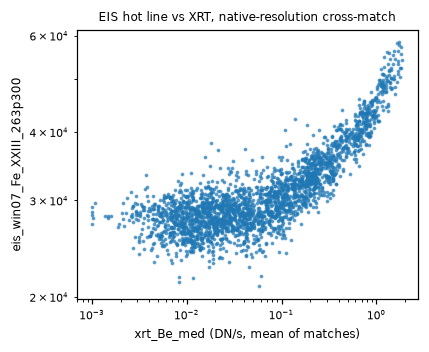

In [10]:
from scipy.spatial import cKDTree
nat = pd.read_parquet(P.aligned / "native.parquet")

def unit(lon, lat):
    lon, lat = np.radians(lon), np.radians(lat)
    return np.c_[np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)]

eis_ch = sorted(c for c in nat.channel.unique() if c.startswith("eis_win07")) or \
         sorted(c for c in nat.channel.unique() if c.startswith("eis_win"))
L = nat[nat.channel == eis_ch[0]].dropna(subset=["lon_carr"])
xch = sorted(c for c in nat.channel.unique() if c.startswith("xrt_"))
Rch = xch[0] if xch else "aia_94"
R = nat[nat.channel == Rch].dropna(subset=["lon_carr"])
# 2 arcsec on the sky ~ 1450 km on the Sun ~ 0.12 heliographic degrees near disk centre
rad = 2 * 725.0 / 696000.0   # radians on the unit sphere (chord ~ angle for small angles)
tree = cKDTree(unit(R.lon_carr, R.lat_carr))
pairs = tree.query_ball_point(unit(L.lon_carr, L.lat_carr), r=rad)
xm = pd.DataFrame({"eis": L["value"].values,
                   "xrt_mean": [R["value"].values[i].mean() if len(i) else np.nan for i in pairs],
                   "n_matched": [len(i) for i in pairs]}).dropna()
print(f"{eis_ch[0]} x {Rch}: {len(xm)} of {len(L)} EIS pixels matched, median {xm.n_matched.median():.0f} XRT px each")
fig, ax = plt.subplots(figsize=(4, 3.3))
ax.loglog(xm.xrt_mean.clip(1e-3), xm.eis.clip(1e-3), ".", ms=3, alpha=0.6)
ax.set_xlabel(f"{Rch} (DN/s, mean of matches)"); ax.set_ylabel(f"{eis_ch[0]}")
ax.set_title("EIS hot line vs XRT, native-resolution cross-match", fontsize=8); plt.tight_layout()

**6c — the same cross-match with LSDB** (optional; the HATS engine planned for Phase 5).
This repeats 6b with the library the full dataset will use, to show that the tables
already fit it. LSDB expects sky coordinates, so Carrington longitude/latitude are passed
as RA/Dec; the matching radius is then an angle on the *solar* sphere (0.12° ≈ 1.45 Mm ≈
2″ near disk centre).

Two differences from 6b when reading the output: LSDB returns only the **nearest** XRT
pixel per EIS pixel (6b returns all within the radius), and its `_dist_arcsec` column is
measured on the solar sphere, not the sky — ~100 "arcsec" there is ~0.03° heliographic,
under 0.5″ on the sky.

In [11]:
try:
    import lsdb
    radius = 0.12 * 3600   # arcsec of *heliographic* angle
    left = lsdb.from_dataframe(L[["lon_carr", "lat_carr", "value"]].rename(columns={"value": "intensity"}),
                               ra_column="lon_carr", dec_column="lat_carr")
    right = lsdb.from_dataframe(R[["lon_carr", "lat_carr", "value"]].rename(columns={"value": "intensity"}),
                                ra_column="lon_carr", dec_column="lat_carr",
                                margin_threshold=2 * radius)   # margin must exceed the match radius
    res = left.crossmatch(right, radius_arcsec=radius, n_neighbors=1, suffixes=("_eis", "_xrt")).compute()
    print(f"LSDB crossmatch: {len(res)} EIS pixels with a nearest XRT pixel within 0.12°")
    display(res.head())
except Exception as e:  # lsdb missing or API change: the KD-tree version above is the reference
    print(f"LSDB step skipped: {type(e).__name__}: {e}")

Computing Catalog:   0%|          | 0/8 [00:00<?, ?it/s]

LSDB crossmatch: 2575 EIS pixels with a nearest XRT pixel within 0.12°


,lon_carr_eis,lat_carr_eis,intensity_eis,lon_carr_xrt,lat_carr_xrt,intensity_xrt,_dist_arcsec
_healpix_29,,,,,,,
1873640591756282044,156.709732,-18.712933,28377.769531,156.697128,-18.725828,0.013898,63.271307
1873641261947548219,156.708618,-18.652744,27982.396484,156.696274,-18.663914,0.004953,58.228922
1873648088252408729,156.70752,-18.592569,29377.167969,156.695435,-18.602015,0.01243,53.450435
1873649876265122459,156.457657,-18.533972,26817.4375,156.438263,-18.540648,0.002365,70.434164
1873648346473645756,156.706421,-18.532406,25446.134766,156.69458,-18.540127,0.016307,49.051136


## 7. Disk usage of this run

Size of each data area for this epoch's data directory: `raw` holds the downloaded files
(kept unchanged as the provenance record), `prep` the calibrated maps, `aligned` the grid
and tables, `manifest` the metadata tables, and `cache` the XRT headers read during
discovery. Only `raw` and `cache` require the network; everything else can be rebuilt
from them.

In [12]:
rows_ = []
for sub in ("raw", "prep", "aligned", "manifest", "cache"):
    d = P.root / sub
    if d.exists():
        rows_.append(dict(area=sub, MB=round(sum(f.stat().st_size for f in d.rglob("*") if f.is_file()) / 1e6, 1)))
du = pd.DataFrame(rows_); du.loc[len(du)] = ["TOTAL", du.MB.sum()]; du

,area,MB
0,raw,12.0
1,prep,27.8
2,aligned,10.6
3,manifest,0.1
4,cache,1.4
5,TOTAL,51.9
